# Solar Filament Segmentation Challenge 2026 — End-to-End Pipeline

Pipeline:
1. **Download** the MAGFiLO dataset (attached Kaggle input, or `kagglehub` with your API token)
2. **Load** COCO-style polygon annotations → binary masks
3. **Train** a U-Net (ResNet34 encoder, 1-channel grayscale input) with BCE + Dice loss
4. **Post-process** probability maps into filament instances (threshold → fragment grouping → small-object removal)
5. **Tune** post-processing on a held-out split using the **Panoptic Quality** metric (the leaderboard metric)
6. **Predict** the test set and write `submission.csv` (`filament_id`, `segmentation_rle` as COCO RLE counts)

## 1. Setup

In [1]:
!pip install -q segmentation-models-pytorch pycocotools kagglehub python-dotenv

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 3.6 MB/s eta 0:00:0000:01


In [2]:
import os, json, random, time
from pathlib import Path
from collections import defaultdict

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from pycocotools import mask as mask_utils
import segmentation_models_pytorch as smp
from tqdm.auto import tqdm

CFG = dict(
    img_size=1024,        # training/inference resolution (originals are 2048x2048)
    encoder='resnet34',
    batch_size=4,
    epochs=25,
    lr=3e-4,
    val_frac=0.15,        # fraction of unique images held out for validation
    seed=42,
    num_workers=0 if os.name == 'nt' else 2,
)
FULL = 2048
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
USE_AMP = DEVICE == 'cuda'

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(CFG['seed'])
print('Device:', DEVICE)

Device: cuda


## 2. Download the dataset
On Kaggle, add the competition data via **+ Add Input** (it appears under `/kaggle/input`).
Locally, `kagglehub` downloads it using `KAGGLE_API_TOKEN` from the environment / `.env`.
You must have accepted the competition rules first.

In [3]:
COMP = 'filament-segmentation-2026'
ANN_NAME = 'MAGFiLO_1.0_Annotations_kaggle2026_train.json'

def locate_dataset(root):
    # Dataset root is the folder containing train/ (which holds the annotation JSON)
    hits = list(Path(root).rglob(ANN_NAME))
    return hits[0].parent.parent if hits else None

DATA_ROOT = locate_dataset('/kaggle/input') if Path('/kaggle/input').exists() else None
if DATA_ROOT is None:
    try:
        from dotenv import load_dotenv
        load_dotenv()
    except ImportError:
        pass
    import kagglehub
    DATA_ROOT = locate_dataset(kagglehub.competition_download(COMP))

assert DATA_ROOT is not None, 'Dataset not found - did you accept the competition rules?'
ANN_PATH = next((DATA_ROOT / 'train').rglob(ANN_NAME))
print('Dataset root:', DATA_ROOT)

Dataset root: /kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026


## 3. Load annotations

In [4]:
IMG_EXTS = ('.jpg', '.jpeg', '.png')

def index_images(d):
    return {p.stem: p for p in Path(d).rglob('*') if p.suffix.lower() in IMG_EXTS}

train_paths = index_images(DATA_ROOT / 'train')
test_paths = index_images(DATA_ROOT / 'test')
print(f'train images: {len(train_paths)}  test images: {len(test_paths)}')

with open(ANN_PATH) as f:
    coco = json.load(f)

anns_by_img = defaultdict(list)
for a in coco['annotations']:
    anns_by_img[str(a['image_id'])].append(a)

# One sample per (annotator, image) pair - multiple annotators of the same image are separate samples
samples = []
for im in coco['images']:
    stem = Path(im['file_name']).stem
    anns = anns_by_img.get(str(im['id']), [])
    if stem in train_paths and anns:
        samples.append(dict(sample_id=str(im['id']), stem=stem, path=train_paths[stem],
                            h=im.get('height', FULL), w=im.get('width', FULL), anns=anns))

print(f"{len(coco['images'])} annotated image entries, {len(coco['annotations'])} filaments")
print(f'{len(samples)} usable samples over {len({s["stem"] for s in samples})} unique images')
assert samples, 'No annotations matched images - check image_id / file_name fields'

train images: 707  test images: 180
1154 annotated image entries, 8199 filaments
1154 usable samples over 707 unique images


In [5]:
def ann_to_mask(ann, h, w):
    seg = ann['segmentation']
    if isinstance(seg, list):
        if seg and isinstance(seg[0], (int, float)):   # flat polygon
            seg = [seg]
        rle = mask_utils.merge(mask_utils.frPyObjects(seg, h, w))
    elif isinstance(seg.get('counts'), list):          # uncompressed RLE
        rle = mask_utils.frPyObjects(seg, h, w)
    else:                                              # compressed RLE
        rle = seg
    return mask_utils.decode(rle).astype(bool)

def instance_masks(s):
    return [ann_to_mask(a, s['h'], s['w']) for a in s['anns']]

def semantic_mask(s):
    m = np.zeros((s['h'], s['w']), np.uint8)
    for im in instance_masks(s):
        m[im] = 1
    return m

def read_gray(path):
    return cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

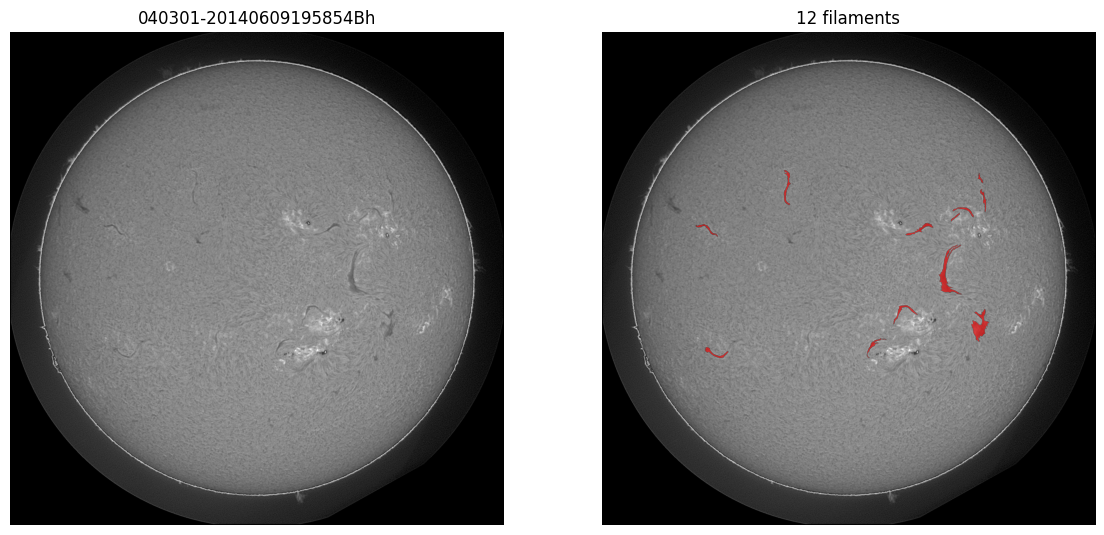

In [6]:
s = samples[0]
img, m = read_gray(s['path']), semantic_mask(s)
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].imshow(img, cmap='gray'); ax[0].set_title(s['sample_id'])
ax[1].imshow(img, cmap='gray'); ax[1].imshow(np.ma.masked_where(m == 0, m), cmap='autumn', alpha=0.6)
ax[1].set_title(f"{len(s['anns'])} filaments")
for a in ax: a.axis('off')
plt.show()

## 4. Train / validation split and caching
Split by **unique image** so annotations of the same image by different annotators never leak across splits.
Images and masks are resized once and cached in memory. Masks are downsampled with area interpolation and kept as soft targets, which preserves thin barbs better than hard thresholding.

In [7]:
S = CFG['img_size']
stems = sorted({s['stem'] for s in samples})
random.Random(CFG['seed']).shuffle(stems)
val_stems = set(stems[:max(1, int(len(stems) * CFG['val_frac']))])
train_samples = [s for s in samples if s['stem'] not in val_stems]
val_samples = [s for s in samples if s['stem'] in val_stems]
print(f'train samples: {len(train_samples)}  val samples: {len(val_samples)}')

def resize_img(img):
    return cv2.resize(img, (S, S), interpolation=cv2.INTER_AREA)

img_cache = {st: resize_img(read_gray(train_paths[st])) for st in tqdm(stems, desc='images')}
mask_cache = {s['sample_id']: cv2.resize(semantic_mask(s) * 255, (S, S), interpolation=cv2.INTER_AREA)
              for s in tqdm(samples, desc='masks')}

train samples: 984  val samples: 170


images:   0%|          | 0/707 [00:00<?, ?it/s]

masks:   0%|          | 0/1154 [00:00<?, ?it/s]

## 5. Dataset, model, loss

In [8]:
def normalize(img_f):
    return (img_f - img_f.mean()) / (img_f.std() + 1e-6)

class FilamentDataset(Dataset):
    def __init__(self, items, train):
        self.items, self.train = items, train
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        s = self.items[i]
        img = img_cache[s['stem']].astype(np.float32) / 255.
        m = mask_cache[s['sample_id']].astype(np.float32) / 255.
        if self.train:
            k = random.randint(0, 3)
            img, m = np.rot90(img, k), np.rot90(m, k)
            if random.random() < 0.5:
                img, m = img[:, ::-1], m[:, ::-1]
            img = np.clip(img * random.uniform(0.85, 1.15) + random.uniform(-0.08, 0.08), 0, 1)
        img = normalize(img)
        return torch.from_numpy(img.copy())[None], torch.from_numpy(m.copy())[None]

train_dl = DataLoader(FilamentDataset(train_samples, True), batch_size=CFG['batch_size'], shuffle=True,
                      num_workers=CFG['num_workers'], drop_last=True, pin_memory=True)
val_dl = DataLoader(FilamentDataset(val_samples, False), batch_size=CFG['batch_size'], shuffle=False,
                    num_workers=CFG['num_workers'])

def build_model(weights='imagenet'):
    return smp.Unet(CFG['encoder'], encoder_weights=weights, in_channels=1, classes=1)

try:
    model = build_model()
except Exception as e:   # e.g. no internet for pretrained weights
    print('Pretrained weights unavailable, training from scratch:', e)
    model = build_model(None)
model = model.to(DEVICE)

bce = nn.BCEWithLogitsLoss()
def dice_loss(logits, target, eps=1.0):
    p = torch.sigmoid(logits)
    num = 2 * (p * target).sum((2, 3)) + eps
    den = p.sum((2, 3)) + target.sum((2, 3)) + eps
    return (1 - num / den).mean()

def criterion(logits, target):
    return bce(logits, target) + dice_loss(logits, target)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

## 6. Train

In [9]:
opt = torch.optim.AdamW(model.parameters(), lr=CFG['lr'], weight_decay=1e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG['lr'], total_steps=CFG['epochs'] * len(train_dl),
                                            pct_start=0.1)
scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
best_dice, history = -1, []

for epoch in range(CFG['epochs']):
    t0 = time.time()
    model.train(); tr_loss = 0
    for x, y in tqdm(train_dl, leave=False, desc=f'epoch {epoch + 1}'):
        x, y = x.to(DEVICE), y.to(DEVICE)
        opt.zero_grad(set_to_none=True)
        with torch.autocast(DEVICE, enabled=USE_AMP):
            loss = criterion(model(x), y)
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update(); sched.step()
        tr_loss += loss.item()

    model.eval(); va_loss, inter, union = 0, 0, 0
    with torch.no_grad():
        for x, y in val_dl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.autocast(DEVICE, enabled=USE_AMP):
                logits = model(x)
            va_loss += criterion(logits.float(), y).item()
            p, t = (logits > 0).float(), (y > 0.5).float()
            inter += (p * t).sum().item(); union += (p.sum() + t.sum()).item()
    dice = 2 * inter / (union + 1e-6)
    history.append((tr_loss / len(train_dl), va_loss / len(val_dl), dice))
    if dice > best_dice:
        best_dice = dice
        torch.save(model.state_dict(), 'best_model.pth')
    print(f'epoch {epoch + 1:02d} | train {history[-1][0]:.4f} | val {history[-1][1]:.4f} '
          f'| val dice {dice:.4f} | {time.time() - t0:.0f}s')

model.load_state_dict(torch.load('best_model.pth', map_location=DEVICE))
print('best val dice:', round(best_dice, 4))

epoch 1:   0%|          | 0/246 [00:00<?, ?it/s]

epoch 01 | train 1.5506 | val 1.3042 | val dice 0.4104 | 109s


epoch 2:   0%|          | 0/246 [00:00<?, ?it/s]

epoch 02 | train 1.1550 | val 1.0131 | val dice 0.6037 | 114s


epoch 3:   0%|          | 0/246 [00:00<?, ?it/s]

...

epoch 23 | train 0.3245 | val 0.3423 | val dice 0.7063 | 116s


epoch 24:   0%|          | 0/246 [00:00<?, ?it/s]

epoch 24 | train 0.3255 | val 0.3419 | val dice 0.7073 | 135s


epoch 25:   0%|          | 0/246 [00:00<?, ?it/s]

epoch 25 | train 0.3242 | val 0.3422 | val dice 0.7069 | 116s
best val dice: 0.7073


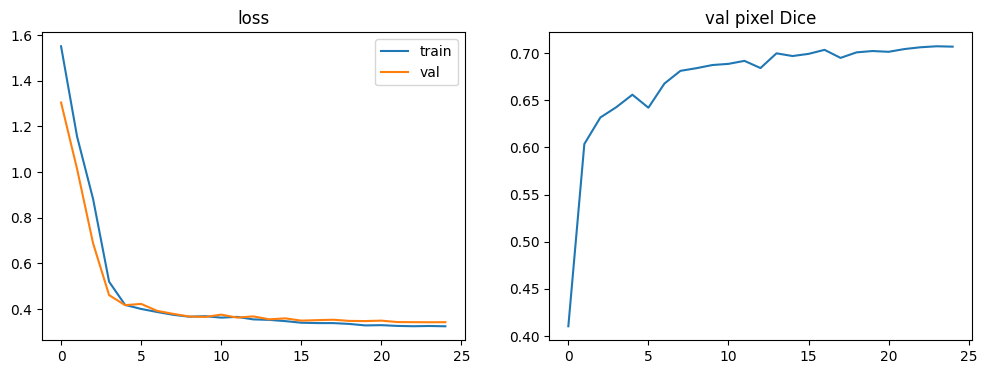

In [10]:
h = np.array(history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h[:, 0], label='train'); ax[0].plot(h[:, 1], label='val'); ax[0].set_title('loss'); ax[0].legend()
ax[1].plot(h[:, 2]); ax[1].set_title('val pixel Dice')
plt.show()

## 7. Post-processing and Panoptic Quality
- **Prediction:** U-Net + horizontal-flip test-time augmentation (TTA), upsampled to 2048×2048
- **Instances:** threshold the probability map, then group nearby fragments by dilating only for labelling (pixels stay exact). This reduces the one-to-many fragmentation penalty. Drop tiny components.
- **PQ** = Σ IoU(TP) / (|TP| + ½|FP| + ½|FN|), where a match requires IoU > 0.5

In [11]:
@torch.no_grad()
def predict_prob(img_small):
    x = torch.from_numpy(normalize(img_small.astype(np.float32) / 255.))[None, None].to(DEVICE)
    with torch.autocast(DEVICE, enabled=USE_AMP):
        p = torch.sigmoid(model(x)) + torch.sigmoid(model(x.flip(-1))).flip(-1)
    prob = (p / 2)[0, 0].float().cpu().numpy()
    return cv2.resize(prob, (FULL, FULL), interpolation=cv2.INTER_LINEAR)

def postprocess(prob, thr=0.5, group_k=21, min_area=200):
    binm = (prob > thr).astype(np.uint8)
    grouping = binm
    if group_k > 0:
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (group_k, group_k))
        grouping = cv2.dilate(binm, kernel)
    n, lab = cv2.connectedComponents(grouping, connectivity=8)
    lab = lab * binm                                   # keep only real foreground pixels
    areas = np.bincount(lab.ravel(), minlength=n)
    return [lab == k for k in range(1, n) if areas[k] >= min_area]

def pq_stats(gt, pred):
    # Returns (sum IoU of matches, TP, FP, FN). IoU > 0.5 guarantees unique matching.
    pred_lab = np.zeros((FULL, FULL), np.int32)
    for i, p in enumerate(pred, 1):
        pred_lab[p] = i
    pred_areas = np.bincount(pred_lab.ravel(), minlength=len(pred) + 1)
    iou_sum, tp, matched = 0.0, 0, set()
    for g in gt:
        inter = np.bincount(pred_lab[g], minlength=len(pred) + 1)
        inter[0] = 0
        j = int(inter.argmax())
        if inter[j] == 0:
            continue
        iou = inter[j] / (g.sum() + pred_areas[j] - inter[j])
        if iou > 0.5:
            iou_sum += iou; tp += 1; matched.add(j)
    return iou_sum, tp, len(pred) - len(matched), len(gt) - tp

def panoptic_quality(stats):
    iou_sum, tp, fp, fn = map(sum, zip(*stats))
    return iou_sum / (tp + 0.5 * fp + 0.5 * fn + 1e-9)

In [12]:
# Cache full-res probabilities (one per unique val image) and GT instances (one set per annotator)
val_probs = {st: predict_prob(img_cache[st]).astype(np.float16) for st in tqdm(sorted(val_stems), desc='val predict')}
val_gt = [(s['stem'], instance_masks(s)) for s in tqdm(val_samples, desc='val gt')]

results = []
for thr in [0.35, 0.5, 0.65]:
    for group_k in [0, 21, 41]:
        for min_area in [100, 400]:
            preds = {st: postprocess(p.astype(np.float32), thr, group_k, min_area) for st, p in val_probs.items()}
            pq = panoptic_quality([pq_stats(gt, preds[st]) for st, gt in val_gt])
            results.append(dict(thr=thr, group_k=group_k, min_area=min_area, PQ=pq))
            print(f'thr={thr:.2f} group_k={group_k:2d} min_area={min_area:3d} -> PQ={pq:.4f}')

res = pd.DataFrame(results).sort_values('PQ', ascending=False)
BEST_PP = res.iloc[0][['thr', 'group_k', 'min_area']].to_dict()
BEST_PP = dict(thr=float(BEST_PP['thr']), group_k=int(BEST_PP['group_k']), min_area=int(BEST_PP['min_area']))
print('Best post-processing:', BEST_PP, '| val PQ =', round(res.iloc[0]['PQ'], 4))

val predict:   0%|          | 0/106 [00:00<?, ?it/s]

val gt:   0%|          | 0/170 [00:00<?, ?it/s]

thr=0.35 group_k= 0 min_area=100 -> PQ=0.3710
thr=0.35 group_k= 0 min_area=400 -> PQ=0.3987
thr=0.35 group_k=21 min_area=100 -> PQ=0.3899
thr=0.35 group_k=21 min_area=400 -> PQ=0.4065
thr=0.35 group_k=41 min_area=100 -> PQ=0.3825
thr=0.35 group_k=41 min_area=400 -> PQ=0.3943
thr=0.50 group_k= 0 min_area=100 -> PQ=0.3679
thr=0.50 group_k= 0 min_area=400 -> PQ=0.3981
thr=0.50 group_k=21 min_area=100 -> PQ=0.3922
thr=0.50 group_k=21 min_area=400 -> PQ=0.4118
thr=0.50 group_k=41 min_area=100 -> PQ=0.3911
thr=0.50 group_k=41 min_area=400 -> PQ=0.4070
thr=0.65 group_k= 0 min_area=100 -> PQ=0.3571
thr=0.65 group_k= 0 min_area=400 -> PQ=0.3850
thr=0.65 group_k=21 min_area=100 -> PQ=0.3854
thr=0.65 group_k=21 min_area=400 -> PQ=0.3990
thr=0.65 group_k=41 min_area=100 -> PQ=0.3832
thr=0.65 group_k=41 min_area=400 -> PQ=0.3926
Best post-processing: {'thr': 0.5, 'group_k': 21, 'min_area': 400} | val PQ = 0.4118


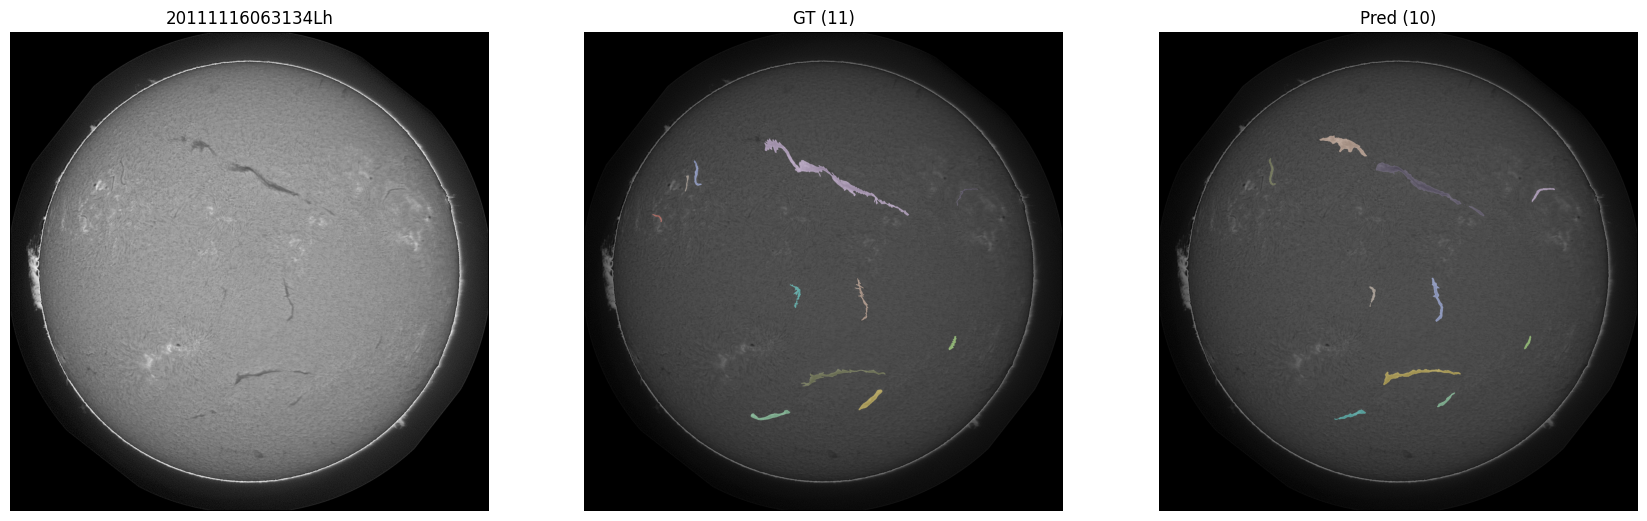

In [13]:
st, gt = val_gt[0]
pred = postprocess(val_probs[st].astype(np.float32), **BEST_PP)
img = read_gray(train_paths[st])

def color_instances(masks):
    out = np.zeros((FULL, FULL, 3), np.uint8)
    rng = np.random.default_rng(0)
    for m in masks:
        out[m] = rng.integers(60, 255, 3)
    return out

fig, ax = plt.subplots(1, 3, figsize=(21, 7))
ax[0].imshow(img, cmap='gray'); ax[0].set_title(st)
ax[1].imshow(img, cmap='gray'); ax[1].imshow(color_instances(gt), alpha=0.5); ax[1].set_title(f'GT ({len(gt)})')
ax[2].imshow(img, cmap='gray'); ax[2].imshow(color_instances(pred), alpha=0.5); ax[2].set_title(f'Pred ({len(pred)})')
for a in ax: a.axis('off')
plt.show()

## 8. Predict the test set and write `submission.csv`

In [14]:
def encode_rle(m):
    return mask_utils.encode(np.asfortranarray(m.astype(np.uint8)))['counts'].decode('ascii')

rows, empty = [], []
for stem, path in tqdm(sorted(test_paths.items()), desc='test'):
    prob = predict_prob(resize_img(read_gray(path)))
    instances = postprocess(prob, **BEST_PP)
    if not instances:
        empty.append(stem)
    for i, m in enumerate(instances, 1):
        rows.append(dict(filament_id=f'{stem}_{i}', segmentation_rle=encode_rle(m)))

sub = pd.DataFrame(rows, columns=['filament_id', 'segmentation_rle'])
sub.to_csv('submission.csv', index=False)
print(f'{len(sub)} filaments over {len(test_paths)} test images -> submission.csv')
if empty:
    print(f'{len(empty)} images with no predicted filaments:', empty[:10])
sub.head()

test:   0%|          | 0/180 [00:00<?, ?it/s]

1139 filaments over 180 test images -> submission.csv
3 images with no predicted filaments: ['20170708164010Mh', '20200310113230Ch', '20211214174010Mh']


,filament_id,segmentation_rle
0,20110120105534Ch_1,h``i23lo1200O001A0lPN0So13jPNNWo13fPNN[o1;0O2N...
1,20110120105534Ch_2,VjTQ24ko11N2O0O110N1000O10N200N12OO100L302I502...
2,20110130110334Ch_1,c_Pe28go14L4M2N3N010kPN^Oin1b0UQN@kn1k00O3M2O1...
3,20110214175414Mh_1,Y]d[27go12M5M1I7O2N2O0O2O0oNZOgRNh0Xm1YOgRNg0W...
4,20110214175414Mh_2,b]Tb24ko1101O1O001O1O01O01000O000001O1O0000000...


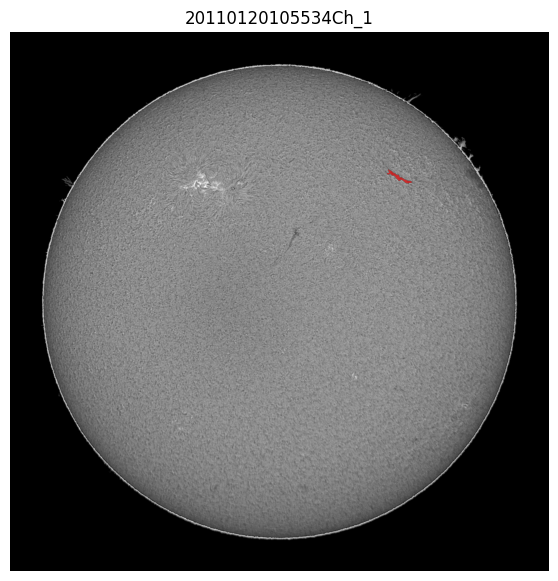

In [15]:
# Sanity check: decode one RLE back and overlay it on its image
r = sub.iloc[0]
m = mask_utils.decode({'size': [FULL, FULL], 'counts': r.segmentation_rle.encode('ascii')})
stem = r.filament_id.rsplit('_', 1)[0]
plt.figure(figsize=(7, 7))
plt.imshow(read_gray(test_paths[stem]), cmap='gray')
plt.imshow(np.ma.masked_where(m == 0, m), cmap='autumn', alpha=0.6)
plt.title(r.filament_id); plt.axis('off'); plt.show()